# Assignment 1: Data Profiling (EDA) Report
**Dataset:** Adult Census Income (UCI)

## Team Members
| Name | Matric No. | Role |
|---|---|---|
| Mohamad Azamuddin | A209604 | Project Lead: Sections 1, 2 and setup |
| Muhammad Qinawee | A210093 | Risk Analysis & Integration: Sections 5, 6, final run-through and submission |
| Nik Aiman Ashraff| A210998 | Data Profiling & Quality Remediation: Section 3 |
| Airell Mikhail | A210140 | Data Visualization & Diagnostic Charts: Section 4 |

## How to Run
1. Clone the repository and open a terminal in its folder.
2. `pip install -r requirements.txt`
3. `jupyter notebook adult_data_profiling.ipynb`
4. Run **Kernel > Restart & Run All**. The data is downloaded automatically (internet required). The cleaned output is saved to `data/adult_clean.csv`.

## 1. Scenario
A government agency or NGO wants to understand which demographic and employment factors are associated with earning more than $50K per year. The Adult Census Income dataset fits this assignment because it contains missing values (in `workclass`, `occupation` and `native-country`), outliers and suspicious values (e.g. `capital-gain`, `hours-per-week`), sensitive attributes (`sex`, `race`, `native-country`) and an imbalanced target.

**Diagnostic questions:**
1. Where are the missing values, and are they random?
2. Which numeric fields contain outliers or invalid values?
3. Does the data carry PII or bias risks that would affect fairness if used for modelling?

## 2. Data Source
- **Dataset:** Adult Census Income, UCI Machine Learning Repository
- **URL:** https://archive.ics.uci.edu/dataset/2/adult
- **Origin:** Extracted from the 1994 US Census database (Becker and Kohavi, 1996)
- **Size:** about 48,842 rows, 14 features and 1 target (`income`)
- **How obtained:** downloaded programmatically with the `ucimlrepo` package (`fetch_ucirepo(id=2)`). No scraping.
- **License:** CC BY 4.0 (verify on the UCI page)
- **Variables:** raw data = `df_raw`, cleaned data = `df_clean`, saved to `data/adult_clean.csv`

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

adult = fetch_ucirepo(id=2)
df_raw = pd.concat([adult.data.features, adult.data.targets], axis=1)
print(df_raw.shape)
df_raw.head()

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Data Profiling and Issue Handling
Variables used by the team: `df_raw` = untouched data, `df` = working copy, `df_clean` = final cleaned data.



In [2]:
# --- Setup (Ash): work on a copy so df_raw stays untouched ---
import numpy as np
import pandas as pd
from pathlib import Path

pd.set_option("display.max_columns", 50)

df = df_raw.copy()
df.columns = [c.replace("-", "_") for c in df.columns]  # hyphens -> underscores for df / df_clean only
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# First look: types, non-null counts, summary
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,47879,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital_status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,47876,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.1 Missing values

In [4]:
# The dataset hides missing values as "?" (and may have stray spaces), so standardise first.
text_cols = df.select_dtypes(include=["object", "string", "category"]).columns
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()
df = df.replace("?", np.nan)

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
})
missing = missing[missing.missing_count > 0].sort_values("missing_pct", ascending=False)
print("Rows with at least one missing value:", df.isna().any(axis=1).sum(),
      f"({df.isna().any(axis=1).mean()*100:.2f}%)")
missing

Rows with at least one missing value: 3620 (7.41%)


,missing_count,missing_pct
occupation,2809,5.75
workclass,2799,5.73
native_country,857,1.75


In [5]:
# Handling: flag + fill with "Unknown" (keep the rows)
df["missing_info_flag"] = df[["workclass", "occupation", "native_country"]].isna().any(axis=1).astype(int)
for c in ["workclass", "occupation", "native_country"]:
    df[c] = df[c].fillna("Unknown")

print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


**Reason (missing values):** The missing values are only in three categorical columns (`workclass`, `occupation`, `native_country`), and the placeholder was `?`, not a real blank. I did **not drop** the rows because that would lose about 7% of the data and could remove a specific group (e.g. people with no job, who naturally have no occupation). I did **not use mode imputation** because it would invent values and make one category look bigger than it is. Instead I labelled them `Unknown` and added `missing_info_flag`, so nothing is hidden and the missingness can still be analysed as its own group.

### 3.2 Outliers

In [6]:
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    z = (df[c] - df[c].mean()) / df[c].std()
    rows.append({
        "column": c, "min": df[c].min(), "max": df[c].max(),
        "IQR_lower": lo, "IQR_upper": hi,
        "IQR_outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
        "IQR_pct": round(((df[c] < lo) | (df[c] > hi)).mean() * 100, 2),
        "zscore>3_outliers": int((z.abs() > 3).sum()),
    })
outlier_summary = pd.DataFrame(rows).set_index("column")
outlier_summary

,min,max,IQR_lower,IQR_upper,IQR_outliers,IQR_pct,zscore>3_outliers
column,,,,,,,
age,17,90,-2.00,78.00,216,0.44,186
fnlwgt,12285,1490400,-62586.75,417779.25,1453,2.97,506
education_num,1,16,4.50,16.50,1794,3.67,330
capital_gain,0,99999,0.00,0.00,4035,8.26,331
capital_loss,0,4356,0.00,0.00,2282,4.67,2216
hours_per_week,1,99,32.50,52.50,13496,27.63,681


In [7]:
# Extra checks for the special cases
print("Share of zeros in capital_gain:", round((df.capital_gain == 0).mean() * 100, 2), "%")
print("Share of zeros in capital_loss:", round((df.capital_loss == 0).mean() * 100, 2), "%")
print("capital_gain == 99999 (top-coded):", (df.capital_gain == 99999).sum())
print(df.hours_per_week.quantile([0.01, 0.05, 0.5, 0.95, 0.99]))

Share of zeros in capital_gain: 91.74 %
Share of zeros in capital_loss: 95.33 %
capital_gain == 99999 (top-coded): 244
0.01     8.00
0.05    17.05
0.50    40.00
0.95    60.00
0.99    80.00
Name: hours_per_week, dtype: float64


In [8]:
# Handling decisions
# 1) age, education_num: keep (valid values) -> nothing to do
# 2) fnlwgt: cap at IQR upper fence (survey weight, not a real-world measurement)
_, fnl_hi = iqr_bounds(df["fnlwgt"])
df["fnlwgt"] = df["fnlwgt"].clip(upper=fnl_hi)

# 3) hours_per_week: cap at 1st and 99th percentile
h_lo, h_hi = df["hours_per_week"].quantile([0.01, 0.99])
df["hours_per_week"] = df["hours_per_week"].clip(lower=h_lo, upper=h_hi)

# 4) capital_gain / capital_loss: keep values, flag the top-coded 99999
df["capital_gain_topcoded"] = (df["capital_gain"] == 99999).astype(int)
print("fnlwgt cap:", round(fnl_hi), "| hours cap:", h_lo, "-", h_hi)

fnlwgt cap: 417779 | hours cap: 8.0 - 80.0


**Reason (outliers):**
- `age`, `education_num`: kept. Flagged ages (older people) and education levels are real, valid values, not errors.
- `fnlwgt`: capped at the IQR upper fence. It is a census sampling weight, not a real measurement, so extreme values add noise rather than information.
- `hours_per_week`: capped at the 1st/99th percentile instead of the IQR fences, because the IQR is very narrow here (most people work 40 hrs) and would wrongly flag normal 55-60 hour weeks. Capping keeps all rows while limiting extreme values.
- `capital_gain` / `capital_loss`: kept. More than 90% of rows are zero, so IQR flags every non-zero value and is not meaningful. The value `99999` is a top-coded placeholder (a cap used by the census), so I added `capital_gain_topcoded` to flag it instead of changing or removing it.

### 3.3 Other quality issues

In [9]:
# --- Inconsistent formats (done BEFORE duplicates): target labels (e.g. "<=50K" vs "<=50K.") ---
print("Before:", df["income"].value_counts().to_dict())
df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
print("After: ", df["income"].value_counts().to_dict())

# Check other text columns for case/spacing variants
for c in df.select_dtypes(include=["object", "string"]).columns:
    raw_n = df[c].nunique()
    norm_n = df[c].str.lower().str.strip().nunique()
    print(f"{c:16s} unique={raw_n:3d}  after lower/strip={norm_n:3d}")

Before: {'<=50K': 24720, '<=50K.': 12435, '>50K': 7841, '>50K.': 3846}
After:  {'<=50K': 37155, '>50K': 11687}
workclass        unique=  9  after lower/strip=  9
education        unique= 16  after lower/strip= 16
marital_status   unique=  7  after lower/strip=  7
occupation       unique= 15  after lower/strip= 15
relationship     unique=  6  after lower/strip=  6
race             unique=  5  after lower/strip=  5
sex              unique=  2  after lower/strip=  2
native_country   unique= 42  after lower/strip= 42
income           unique=  2  after lower/strip=  2


In [10]:
# --- Duplicates ---
dups = df.duplicated().sum()
print("Exact duplicate rows:", dups, f"({dups/len(df)*100:.2f}%)")
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows:", n_before, "->", len(df))

Exact duplicate rows: 63 (0.13%)
Rows: 48842 -> 48779


In [11]:
# --- Invalid values ---
checks = {
    "age outside 17-90": ((df.age < 17) | (df.age > 90)).sum(),
    "hours_per_week <= 0": (df.hours_per_week <= 0).sum(),
    "negative capital_gain/loss": ((df.capital_gain < 0) | (df.capital_loss < 0)).sum(),
    "education_num outside 1-16": ((df.education_num < 1) | (df.education_num > 16)).sum(),
    "education <-> education_num mismatch": int((df.groupby("education")["education_num"].nunique() > 1).sum()),
    "negative fnlwgt": (df.fnlwgt < 0).sum(),
}
pd.Series(checks, name="invalid_count")

age outside 17-90                       0
hours_per_week <= 0                     0
negative capital_gain/loss              0
education_num outside 1-16              0
education <-> education_num mismatch    0
negative fnlwgt                         0
Name: invalid_count, dtype: int64

In [12]:
# --- Data types ---
print(df.dtypes)
cat_cols = ["workclass", "education", "marital_status", "occupation", "relationship",
            "race", "sex", "native_country", "income"]
df[cat_cols] = df[cat_cols].astype("category")
int_cols = ["age", "education_num", "capital_gain", "capital_loss"]
df[int_cols] = df[int_cols].astype("int64")
print()
print(df.dtypes)

age                        int64
workclass                 string
fnlwgt                   float64
education                 string
education_num              int64
marital_status            string
occupation                string
relationship              string
race                      string
sex                       string
capital_gain               int64
capital_loss               int64
hours_per_week             int64
native_country            string
income                    string
missing_info_flag          int64
capital_gain_topcoded      int64
dtype: object

age                         int64
workclass                category
fnlwgt                    float64
education                category
education_num               int64
marital_status           category
occupation               category
relationship             category
race                     category
sex                      category
capital_gain                int64
capital_loss                int64
hours_per_week  

**Reason (other issues):**
- **Duplicates:** I dropped exact duplicate rows, after fixing the income labels first, so rows that only differed by a trailing `.` (train vs test file) are also caught. The data has no ID column, but because `fnlwgt` (a near-unique weight) is compared too, a fully identical row is far more likely to be a repeated record than a different person.
- **Inconsistent labels:** the target `income` has the same class written two ways (e.g. `<=50K` and `<=50K.`, from the train/test files). I merged them, otherwise one class would be split into two.
- **Invalid values:** I checked age, hours, education and capital values against valid ranges. Any non-zero count above would be handled as invalid; zero means no fix was needed.
- **Data types:** text columns were converted to `category` (less memory, clear groups) and numeric columns to integers.

### 3.4 Before / after summary and handover

In [13]:
df_clean = df.copy()

summary = pd.DataFrame({
    "raw": [df_raw.shape[0], df_raw.shape[1], int(df_raw.replace(r"^\s*\?\s*$", np.nan, regex=True).isna().sum().sum()), int(df_raw.duplicated().sum())],
    "clean": [df_clean.shape[0], df_clean.shape[1], int(df_clean.isna().sum().sum()), int(df_clean.duplicated().sum())],
}, index=["rows", "columns", "missing cells", "duplicate rows"])
display(summary)

Path("data").mkdir(exist_ok=True)
df_clean.to_csv("data/adult_clean.csv", index=False)
df_clean.head()

,raw,clean
rows,48842,48779
columns,15,17
missing cells,6465,0
duplicate rows,29,0


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,missing_info_flag,capital_gain_topcoded
0,39,State-gov,77516.0,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0,0
1,50,Self-emp-not-inc,83311.0,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0,0
2,38,Private,215646.0,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0,0
3,53,Private,234721.0,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0,0
4,28,Private,338409.0,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0,0


## 4. Exploratory (Diagnostic) Charts


In [14]:
print(df_raw.shape)
print(df_raw.columns.tolist())
print(df_raw.isna().sum())
print((df_raw["workclass"] == "?").sum())

(48842, 15)
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64
1836


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df_plot = df_raw.copy()
df_plot = df_plot.replace("?", np.nan)

print(df_plot.isna().sum())

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64


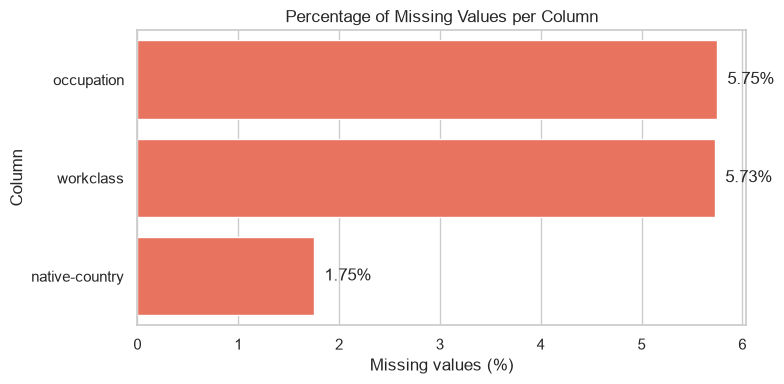

In [21]:
miss_pct = df_plot.isna().mean() * 100
miss_pct = miss_pct[miss_pct > 0]
miss_pct = miss_pct.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=miss_pct.values, y=miss_pct.index, color="tomato", ax=ax)

ax.set_title("Percentage of Missing Values per Column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")

for i, v in enumerate(miss_pct.values):
    ax.text(v + 0.1, i, f"{v:.2f}%", va="center")

plt.tight_layout()
plt.show()

**What this chart exposes:** Only three columns contain missing values: `occupation` (5.75%), `workclass` (5.73%) and `native-country` (1.75%). `occupation` and `workclass` are the most affected, with about 5.7% of rows missing each. These problems are hidden in the raw data because missing values are stored in two different ways: real `NaN` and the text `"?"`. Counting only `NaN` with `isna()` gives just 963 missing values for `workclass`, while the true number is 2,799 once `"?"` is also counted. If this is not standardised first, the missing values are under-counted by more than half.

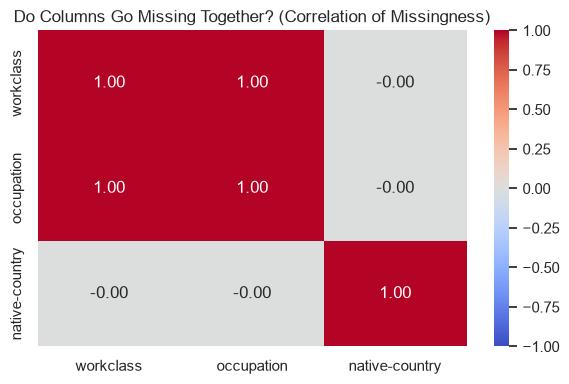

In [17]:
miss_cols = ["workclass", "occupation", "native-country"]
miss_corr = df_plot[miss_cols].isna().astype(int).corr()

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(miss_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Do Columns Go Missing Together? (Correlation of Missingness)")

plt.tight_layout()
plt.show()

**What this chart exposes:** `workclass` and `occupation` have a missingness correlation of 1.00, which means they are missing in almost the same rows (2,799 vs 2,809 missing). `native-country` has a correlation of about 0 with both, so it goes missing independently. Because `workclass` and `occupation` are missing together, the missing values are probably not random: they likely belong to one specific group, such as people without a recorded job. Dropping these rows would remove that group from the data and bias the sample, so it is safer to keep them and flag them as `Unknown`.

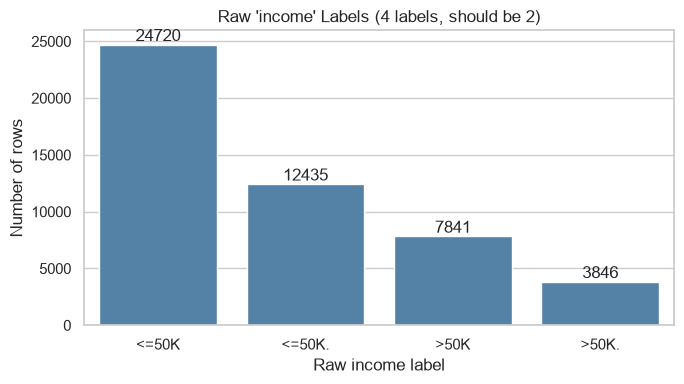

In [18]:
order = df_raw["income"].value_counts().index

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df_raw, x="income", order=order, color="steelblue", ax=ax)

ax.set_title("Raw 'income' Labels (4 labels, should be 2)")
ax.set_xlabel("Raw income label")
ax.set_ylabel("Number of rows")

for cont in ax.containers:
    ax.bar_label(cont)

plt.tight_layout()
plt.show()

**What this chart exposes:** The target column `income` has four labels instead of two: `<=50K` (24,720), `<=50K.` (12,435), `>50K` (7,841) and `>50K.` (3,846). The classes are the same, but the labels with a trailing `.` come from the UCI test file, which is written differently from the training file. If they are not merged, each class is split in two and counts, group comparisons and model training will be wrong. After merging, the real totals are 37,155 for `<=50K` and 11,687 for `>50K`, which is also an imbalanced target (about 76% vs 24%).

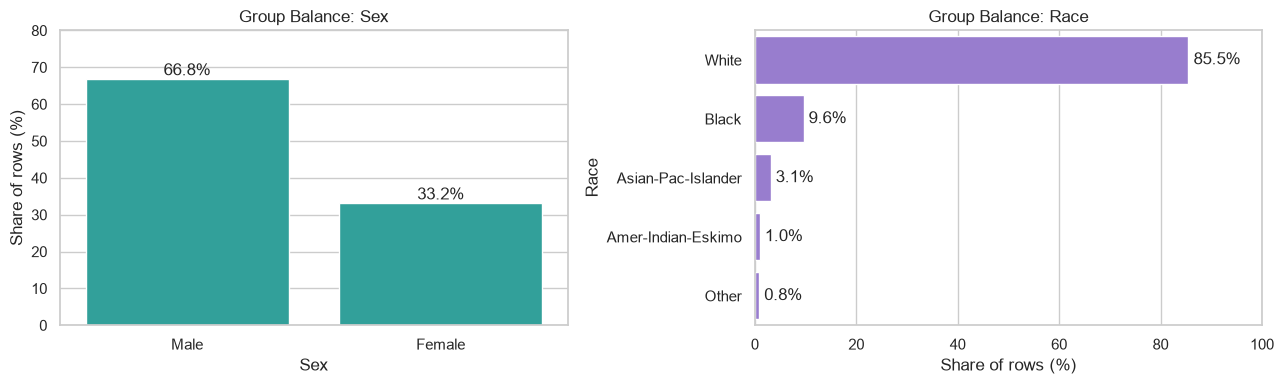

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Sex
sex_pct = df_raw["sex"].value_counts(normalize=True) * 100
sns.barplot(x=sex_pct.index, y=sex_pct.values, color="lightseagreen", ax=axes[0])
axes[0].set_title("Group Balance: Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Share of rows (%)")
axes[0].set_ylim(0, 80)
for i, v in enumerate(sex_pct.values):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center")

# Race
race_pct = df_raw["race"].value_counts(normalize=True) * 100
sns.barplot(x=race_pct.values, y=race_pct.index, color="mediumpurple", ax=axes[1])
axes[1].set_title("Group Balance: Race")
axes[1].set_xlabel("Share of rows (%)")
axes[1].set_ylabel("Race")
axes[1].set_xlim(0, 100)
for i, v in enumerate(race_pct.values):
    axes[1].text(v + 1, i, f"{v:.1f}%", va="center")

plt.tight_layout()
plt.show()

**What this chart exposes:** The groups in the data are not balanced. Males make up 66.8% of rows and females 33.2%. For race, White individuals make up 85.5% of rows, while Asian-Pac-Islander (3.1%), Amer-Indian-Eskimo (1.0%) and Other (0.8%) each have very few rows. A model trained on this data sees many more examples of the majority groups, so it can perform worse for small groups and may learn the patterns of the majority as if they applied to everyone. This is a representation bias risk (see Section 5), and results should be reported per group instead of using overall accuracy only.

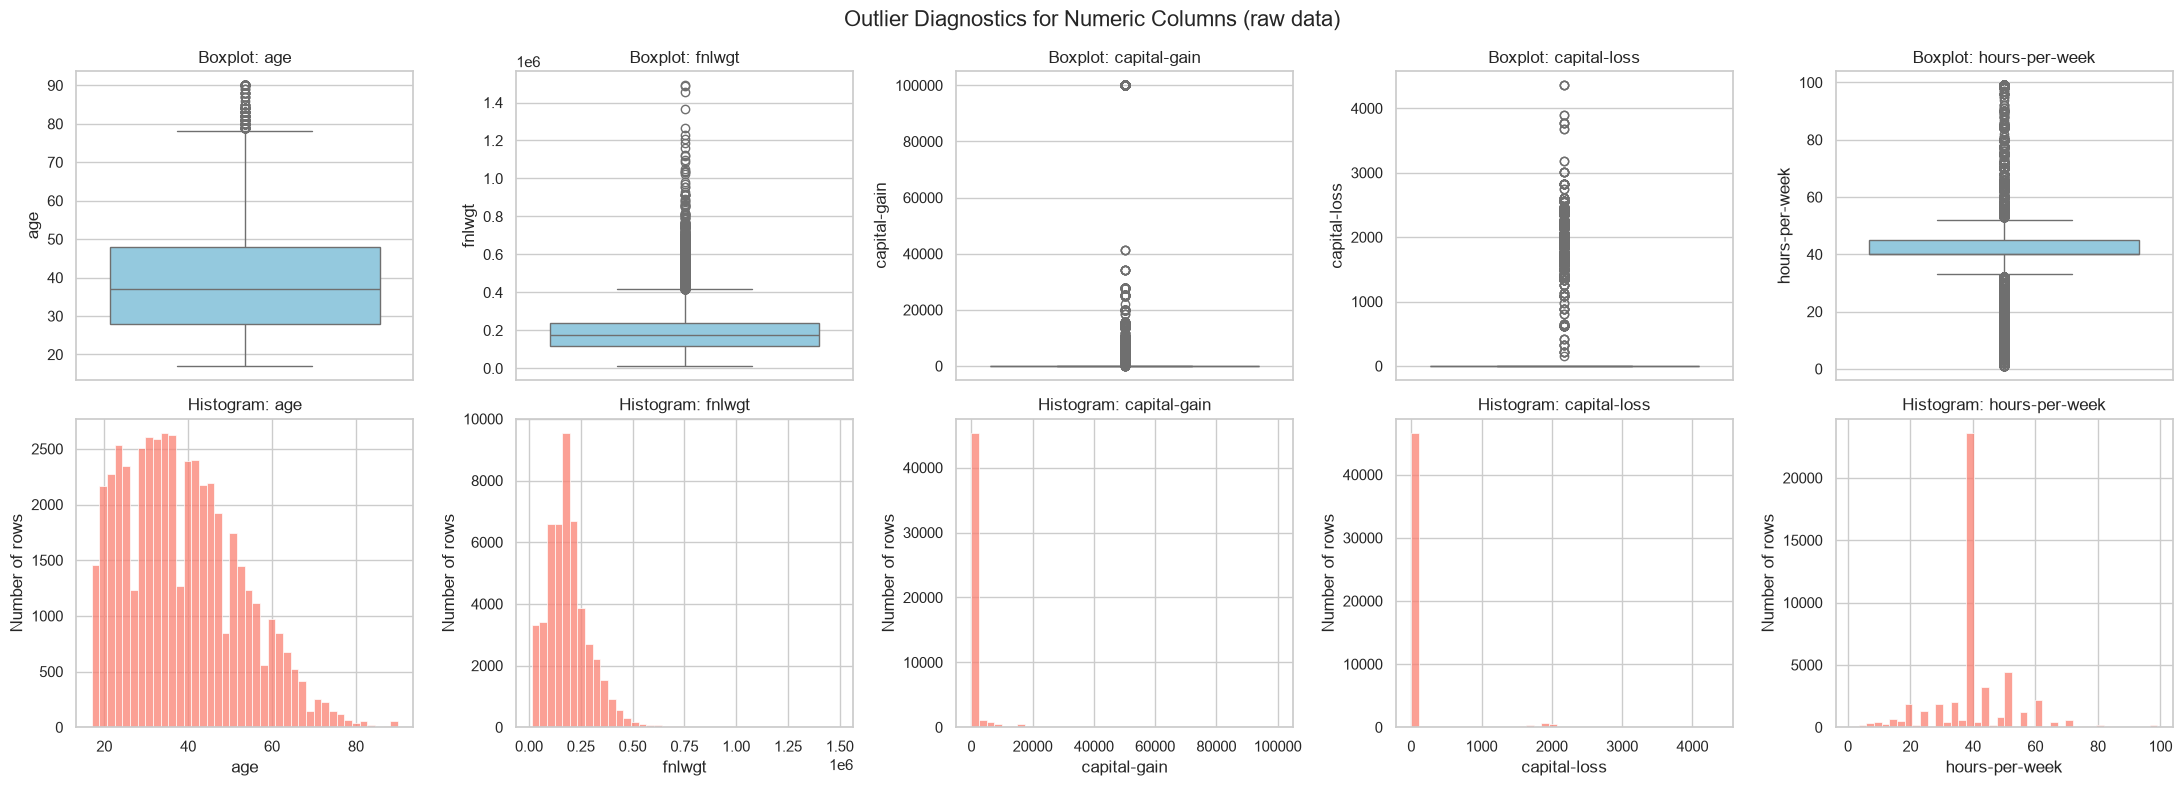

capital-gain == 0 (%): 91.74
capital-gain == 99999 (rows): 244


In [22]:
num_raw = ["age", "fnlwgt", "capital-gain", "capital-loss", "hours-per-week"]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for i, col in enumerate(num_raw):
    sns.boxplot(y=df_raw[col], ax=axes[0, i], color="skyblue")
    axes[0, i].set_title(f"Boxplot: {col}")
    sns.histplot(df_raw[col], bins=40, ax=axes[1, i], color="salmon")
    axes[1, i].set_title(f"Histogram: {col}")
    axes[1, i].set_xlabel(col)
    axes[1, i].set_ylabel("Number of rows")

fig.suptitle("Outlier Diagnostics for Numeric Columns (raw data)", fontsize=16)
plt.tight_layout()
plt.show()

print("capital-gain == 0 (%):", round((df_raw["capital-gain"] == 0).mean() * 100, 2))
print("capital-gain == 99999 (rows):", int((df_raw["capital-gain"] == 99999).sum()))

### 5.1 PII (Personally Identifiable Information) Risk

**Risk:** The dataset contains no direct identifiers (no names, ID numbers, addresses or phone numbers). However, it contains quasi-identifiers: `age`, `sex`, `race`, `native-country`, `marital-status`, `education` and `occupation`. Combined, they can single out individuals, especially people in rare groups (e.g. an older woman from a small country with an uncommon occupation).

**Evidence:** Sensitive attributes (race, sex, marital status, country of origin) are present for every record, and `native-country` has many rare categories with very few rows.

**Impact:** Linking this data with another dataset could re-identify individuals and reveal their income bracket.

**Mitigation:** (1) Generalise `age` into bands (e.g. 17-25, 26-35). (2) Group `native-country` into regions and merge rare countries into "Other". (3) Drop `fnlwgt` and any column not needed for the scenario. (4) Do not publish row-level data beyond this public dataset. (5) Check that every combination of quasi-identifiers appears in at least k records (k-anonymity).

### 5.2 Sampling Bias

**Risk:** The data was extracted from the 1994 US Census (Becker and Kohavi, 1996) using filters on age, income and working hours, so it is neither current nor representative of other countries or of the full population.

**Evidence:** In the raw data, 89.7% of records are from the United States and 85.5% are White. Black individuals make up 9.6%, Asian-Pacific Islanders 3.1%, American Indian/Eskimo 1.0% and Other 0.8%. Non-US countries and minority groups therefore appear in very small numbers.

**Impact:** Findings may not generalise to other countries, ethnic groups or the present day. Wages and job structures from 1994 are outdated.

**Mitigation:** State clearly that conclusions apply only to the 1994 US context, avoid generalising to other populations, and collect newer, more diverse data before any real decision-making.

### 5.3 Imbalanced Groups

**Risk:** Both the target and the sensitive groups are imbalanced.

**Evidence:** Only 23.9% of records earn >50K versus 76.1% earning <=50K. Males make up 66.8% of records and females 33.2%. About 30.4% of men earn >50K compared to 10.9% of women, so `sex` is strongly linked to the target.

**Impact:** A model or analysis can favour the majority group, report misleadingly high overall accuracy, and learn historical gender or racial inequality as if it were a rule.

**Mitigation:** Use stratified sampling, resampling or class weights; report metrics per group (precision and recall by sex and race) instead of overall accuracy only; and avoid using `sex` and `race` directly as predictors unless the scenario explicitly requires it.

### 5.4 Missing Data as a Hidden Bias

**Risk:** Missing values in `workclass`, `occupation` and `native-country` may not be random.

**Impact:** Dropping these rows could remove certain groups (e.g. unemployed or less-documented workers) and shift the group proportions.

**Mitigation:** Compare group proportions before and after cleaning (see Section 3) and keep "missing" as its own category where appropriate.

*Note: percentages above are from the raw data (`df_raw`) before cleaning.*

In [20]:
high = df_raw['income'].str.contains('>50K')

print(df_raw['sex'].value_counts(normalize=True).round(3))
print(df_raw['race'].value_counts(normalize=True).round(3))
print('US:', (df_raw['native-country'] == 'United-States').mean().round(3))
print('>50K:', high.mean().round(3))
print((high.groupby(df_raw['sex']).mean() * 100).round(1))

sex
Male      0.668
Female    0.332
Name: proportion, dtype: float64
race
White                 0.855
Black                 0.096
Asian-Pac-Islander    0.031
Amer-Indian-Eskimo    0.010
Other                 0.008
Name: proportion, dtype: float64
US: 0.897
>50K: 0.239
sex
Female    10.9
Male      30.4
Name: income, dtype: float64


## 6. Conclusion
**Fitness for the scenario:** The Adult Census dataset is **partially fit** for the scenario. It is large, well documented and contains relevant demographic and employment variables, so it is suitable for exploring which factors are associated with earning more than $50K. However, it is **not fit for real-world decisions** about current populations, because the data is from 1994 and demographically narrow.

**Answers to the diagnostic questions:**
1. *Missing values:* located in `workclass`, `occupation` and `native-country` (see Section 3 for whether they are random).
2. *Outliers and invalid values:* found in numeric fields such as `capital-gain` and `hours-per-week` (see Sections 3 and 4).
3. *PII and bias risks:* the data has no direct identifiers, but quasi-identifiers, sampling bias (1994 US only) and group imbalance (sex, race, income) create fairness risks (see Section 5).

**What was improved:** Missing values were handled and justified, outliers were examined, duplicates and inconsistent formats were fixed, and data types were corrected (see Section 3). The diagnostic charts (Section 4) confirmed the main data quality problems.

**Remaining limitations:**
1. The data is from 1994 and reflects the US only, so it is not representative of today or of other countries.
2. Group imbalances (sex, race, native country and income class) remain and can bias any model or conclusion.
3. Quasi-identifiers could allow re-identification if combined with other data.
4. Imputed or flagged values add uncertainty.
5. Associations found here are not causal.

**Recommendation:** Use this dataset for learning and exploratory analysis only. Report results per group, document all cleaning decisions, and use newer and more representative data before applying findings in practice.